In [2]:
"""
Image metrics for corrected seed-conditioned GENERATED COLONY PATTERNS.
All comparisons use final colony images on the same 132-image held-out cohort:
  1. Experimental colony patterns vs simulated colony patterns.
  2. Experimental colony patterns vs generated colony patterns.
  3. Simulated colony patterns vs generated colony patterns.
"Seed-conditioned" describes the generator's conditioning, not a seed-map
image being used as a reference. No seed maps enter these metrics or plots.
"""

'\nImage metrics for corrected seed-conditioned GENERATED COLONY PATTERNS.\nAll comparisons use final colony images on the same 132-image held-out cohort:\n  1. Experimental colony patterns vs simulated colony patterns.\n  2. Experimental colony patterns vs generated colony patterns.\n  3. Simulated colony patterns vs generated colony patterns.\n"Seed-conditioned" describes the generator\'s conditioning, not a seed-map\nimage being used as a reference. No seed maps enter these metrics or plots.\n'

In [3]:
import torch
import numpy as np
import matplotlib.pyplot as plt

from cldm.metrics import (
    display_images_with_ssim,
    calculate_lpips_score_batch,
    calculate_orb_similarity_batch,
    calculate_ssim_batch,
)

Setting up [LPIPS] perceptual loss: trunk [vgg], v[0.1], spatial [off]


/hpc/dctrl/ks723/miniconda3/envs/pytorch_PA_patternprediction/lib/python3.10/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/hpc/dctrl/ks723/miniconda3/envs/pytorch_PA_patternprediction/lib/python3.10/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=VGG16_Weights.IMAGENET1K_V1`. You can also use `weights=VGG16_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Loading model from: /hpc/dctrl/ks723/miniconda3/envs/pytorch_PA_patternprediction/lib/python3.10/site-packages/lpips/weights/v0.1/vgg.pth


In [4]:
from image_metric_evaluation import (
    build_test_manifest, load_test_images, evaluate_metrics, metric_scores,
    cmmd_from_embeddings, DEFAULT_OUTPUT_DIR,
)
manifest = build_test_manifest(include_fixed=True, fixed_sample=1, seed_sample=1)
images = load_test_images(manifest)
exp_images = images['experiment']
sim_images = images['simulation']
pred_images = images['seed_conditioned']  # Generated final colony patterns.
RESULTS_DIR = DEFAULT_OUTPUT_DIR
RECOMPUTE_METRICS = False
print('Matched colony-pattern images:', len(manifest), '(96 primary + 36 fixed)')
for label, batch in [('Experiment', exp_images), ('Simulation', sim_images),
                     ('Generated colony pattern (seed-conditioned)', pred_images)]:
    print(f'{label}: {tuple(batch.shape)}')

Matched colony-pattern images: 132 (96 primary + 36 fixed)
Experiment: (132, 3, 256, 256)
Simulation: (132, 3, 256, 256)
Generated colony pattern (seed-conditioned): (132, 3, 256, 256)


Sample 0: ref_image.shape = (3, 256, 256), comp_image.shape = (3, 256, 256)
Sample 1: ref_image.shape = (3, 256, 256), comp_image.shape = (3, 256, 256)
Sample 2: ref_image.shape = (3, 256, 256), comp_image.shape = (3, 256, 256)
Sample 3: ref_image.shape = (3, 256, 256), comp_image.shape = (3, 256, 256)
Sample 4: ref_image.shape = (3, 256, 256), comp_image.shape = (3, 256, 256)


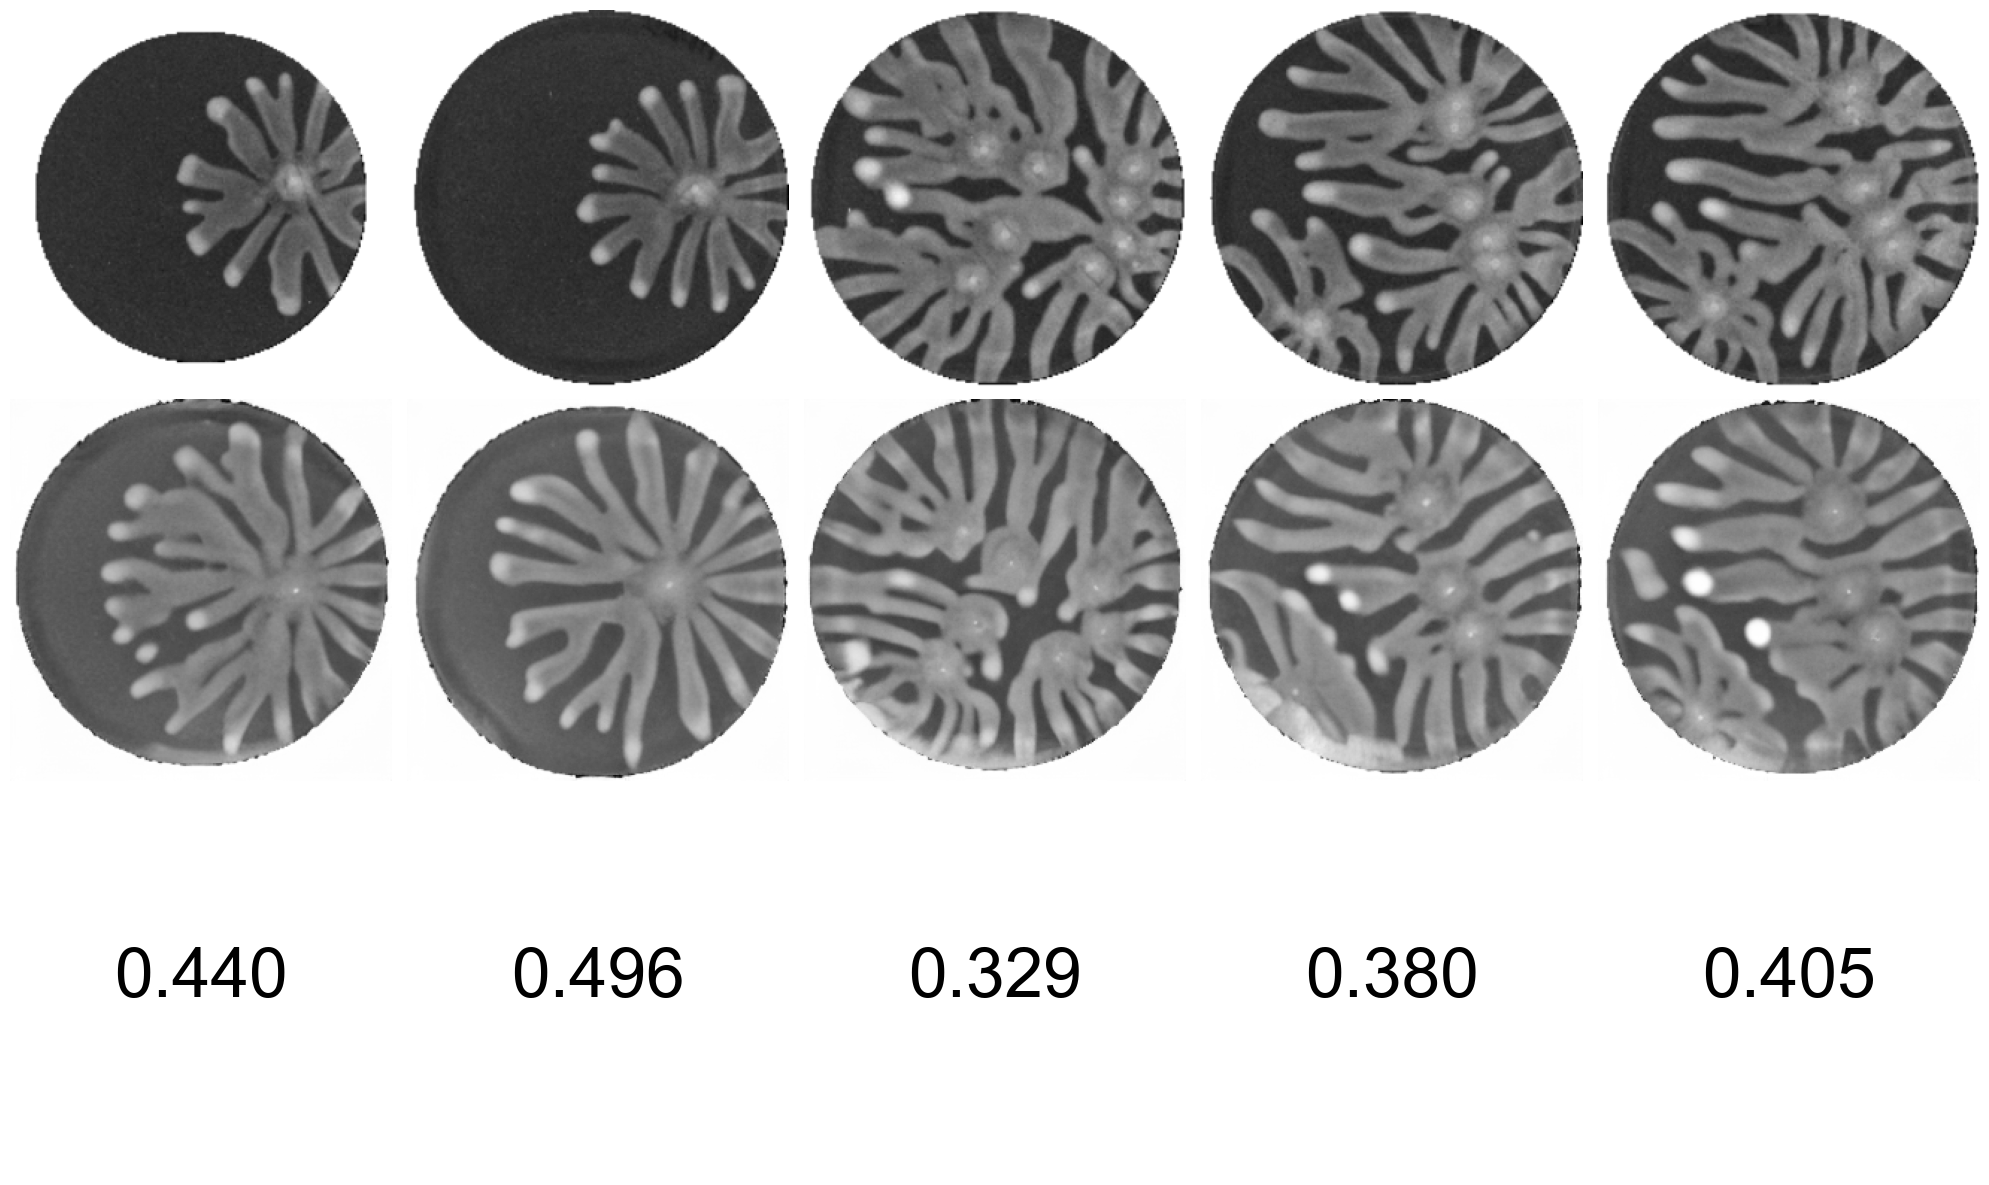

In [5]:
# Experimental colony patterns versus generated colony patterns.
selected_indices = [4, 5, 2, 6, 7]
display_images_with_ssim(exp_images[selected_indices], pred_images[selected_indices], num_samples=5)

Sample 0: ref_image.shape = (3, 256, 256), comp_image.shape = (3, 256, 256)
Sample 1: ref_image.shape = (3, 256, 256), comp_image.shape = (3, 256, 256)
Sample 2: ref_image.shape = (3, 256, 256), comp_image.shape = (3, 256, 256)
Sample 3: ref_image.shape = (3, 256, 256), comp_image.shape = (3, 256, 256)
Sample 4: ref_image.shape = (3, 256, 256), comp_image.shape = (3, 256, 256)


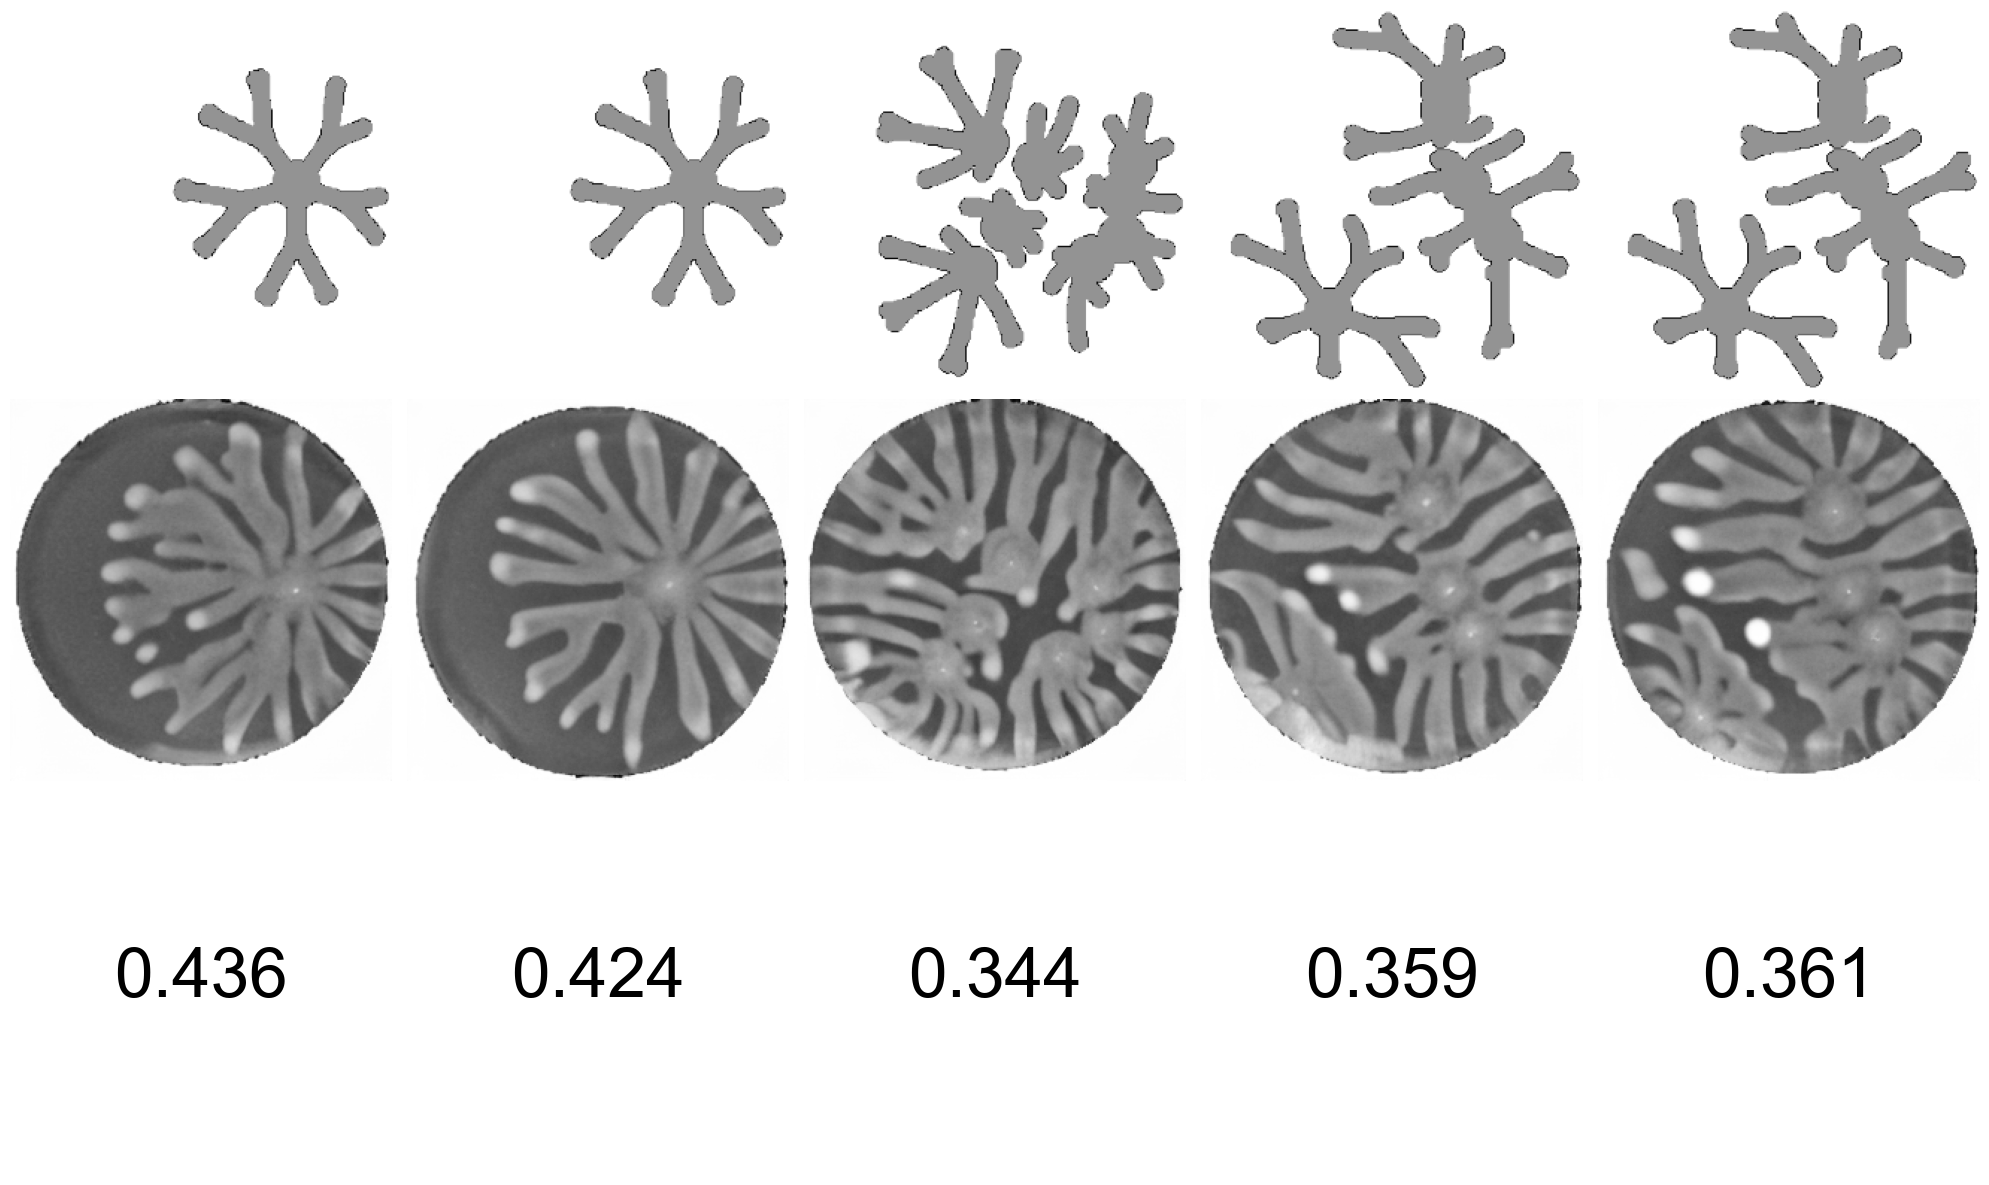

In [6]:
# Simulated colony patterns versus generated colony patterns.
selected_indices = [4, 5, 2, 6, 7]
display_images_with_ssim(sim_images[selected_indices], pred_images[selected_indices], num_samples=5)

In [7]:
# Reuse the existing experiment/simulation and experiment/generation results.
evaluation = evaluate_metrics(manifest, images, RESULTS_DIR,
                              recompute=RECOMPUTE_METRICS, clip_batch_size=8)
lpips_genAI = metric_scores(evaluation, 'exp_seed', 'lpips')
lpips_sim = metric_scores(evaluation, 'exp_sim', 'lpips')
lpips_simgenAI = calculate_lpips_score_batch(sim_images, pred_images)

Loaded matched 132-image metrics from /hpc/dctrl/ks723/Physics_constrained_DL_pattern_prediction/sim_to_exp_diffusion/controlnet_essential/image_metrics_full_test/combined132


In [8]:
orb_similarity_genAI = metric_scores(evaluation, 'exp_seed', 'orb')
orb_similarity_sim = metric_scores(evaluation, 'exp_sim', 'orb')
orb_similarity_simgenAI = calculate_orb_similarity_batch(sim_images, pred_images)

In [9]:
ssim_similarity_genAI = metric_scores(evaluation, 'exp_seed', 'ssim')
ssim_similarity_sim = metric_scores(evaluation, 'exp_sim', 'ssim')
ssim_similarity_simgenAI = calculate_ssim_batch(sim_images, pred_images)

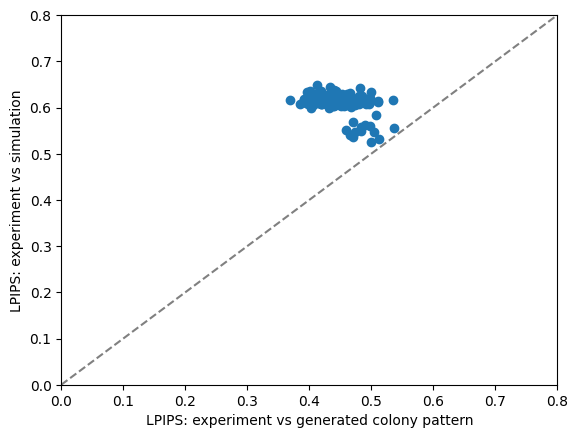

In [10]:
# Compare each method with the SAME experimental reference image.
plt.scatter(lpips_genAI, lpips_sim)
x = np.linspace(0, 0.8, 100)
plt.plot(x, x, color='gray', linestyle='--', label='y = x')
plt.xlabel('LPIPS: experiment vs generated colony pattern')
plt.ylabel('LPIPS: experiment vs simulation')
plt.xlim([0, 0.8])
plt.ylim([0, 0.8])
plt.show()

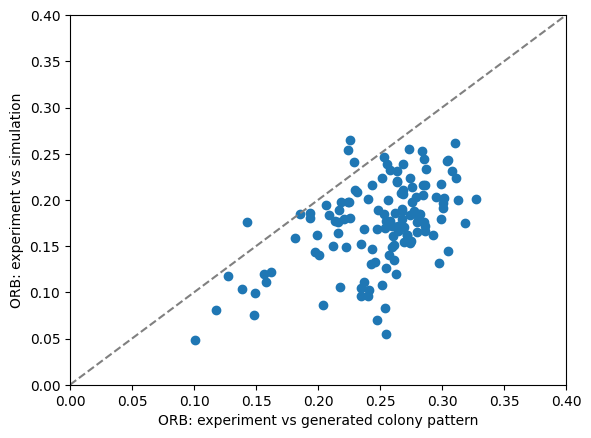

In [11]:
# Compare each method with the SAME experimental reference image.
plt.scatter(orb_similarity_genAI, orb_similarity_sim)
x = np.linspace(0, 0.4, 100)
plt.plot(x, x, color='gray', linestyle='--', label='y = x')
plt.xlabel('ORB: experiment vs generated colony pattern')
plt.ylabel('ORB: experiment vs simulation')
plt.xlim([0, 0.4])
plt.ylim([0, 0.4])
plt.show()

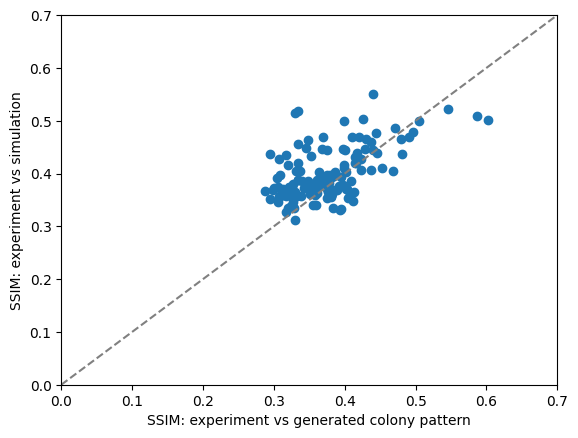

In [12]:
# Compare each method with the SAME experimental reference image.
plt.scatter(ssim_similarity_genAI, ssim_similarity_sim)
x = np.linspace(0, 0.7, 100)
plt.plot(x, x, color='gray', linestyle='--', label='y = x')
plt.xlabel('SSIM: experiment vs generated colony pattern')
plt.ylabel('SSIM: experiment vs simulation')
plt.xlim([0, 0.7])
plt.ylim([0, 0.7])
plt.show()

In [13]:
from pathlib import Path as _DataPath
import sys as _data_sys
_DATA_ROOT = next(p for p in (_DataPath.cwd(), *_DataPath.cwd().parents) if (p / 'paper_paths.py').is_file())
if str(_DATA_ROOT) not in _data_sys.path: _data_sys.path.insert(0, str(_DATA_ROOT))
from paper_paths import figure_source_path as _figure_source_path
# Save and summarize only comparisons between FINAL COLONY PATTERNS.
import csv
import json
from pathlib import Path

comparisons = {
    'exp_sim': ('Experiment / simulation', lpips_sim, ssim_similarity_sim, orb_similarity_sim),
    'exp_seed': ('Experiment / generated colony pattern (seed-conditioned)',
                 lpips_genAI, ssim_similarity_genAI, orb_similarity_genAI),
    'sim_seed': ('Simulation / generated colony pattern (seed-conditioned)',
                 lpips_simgenAI, ssim_similarity_simgenAI, orb_similarity_simgenAI),
}
per_image_rows, summary_rows, cmmd_rows = [], [], []
for comparison, (label, lpips_values, ssim_values, orb_values) in comparisons.items():
    metric_arrays = {'lpips': lpips_values, 'ssim': ssim_values, 'orb': orb_values}
    for metric, values in metric_arrays.items():
        assert len(values) == len(manifest) and np.isfinite(values).all()
        print(f'{label}, {metric.upper()}: {np.mean(values):.4f} ± {np.std(values):.4f}')
    for index, row in enumerate(manifest):
        per_image_rows.append({
            'image_id': row['image_id'], 'subset': row['subset'],
            'configuration_id': row['configuration_id'], 'comparison': comparison,
            **{metric: float(values[index]) for metric, values in metric_arrays.items()},
        })
    for subset in ('all', 'primary', 'fixed'):
        indices = [i for i, row in enumerate(manifest)
                   if subset == 'all' or row['subset'] == subset]
        for metric, values in metric_arrays.items():
            summary_rows.append(dict(comparison=comparison, subset=subset,
                                     metric=metric, n_images=len(indices),
                                     mean=float(values[indices].mean()),
                                     std=float(values[indices].std(ddof=0))))

# Reuse the already computed CLIP embeddings in exactly the same manifest order.
with np.load(_figure_source_path(RESULTS_DIR / 'clip_embeddings.npz')) as saved:
    embedding_pairs = {
        'exp_sim': (saved['experiment'], saved['simulation']),
        'exp_seed': (saved['experiment'], saved['seed_conditioned']),
        'sim_seed': (saved['simulation'], saved['seed_conditioned']),
    }
    for comparison, (reference, target) in embedding_pairs.items():
        assert len(reference) == len(target) == len(manifest)
        for subset in ('all', 'primary', 'fixed'):
            indices = [i for i, row in enumerate(manifest)
                       if subset == 'all' or row['subset'] == subset]
            value = cmmd_from_embeddings(reference[indices], target[indices])
            cmmd_rows.append(dict(comparison=comparison, subset=subset,
                                  n_reference=len(indices), n_target=len(indices), cmmd=value))
            print(f"{comparisons[comparison][0]}, CMMD ({subset}, n={len(indices)}): {value:.6f}")

for filename, rows in [
    ('seed_conditioned_notebook_per_image_metrics.csv', per_image_rows),
    ('seed_conditioned_notebook_summary_metrics.csv', summary_rows),
    ('seed_conditioned_notebook_cmmd_metrics.csv', cmmd_rows),
]:
    with (RESULTS_DIR / filename).open('w', newline='') as handle:
        writer = csv.DictWriter(handle, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)
settings = {
    'source_notebook': 'inference_quantmetrics_seedtoexp.ipynb',
    'n_images': len(manifest),
    'comparisons': {key: value[0] for key, value in comparisons.items()},
    'reference_image_type': 'Final simulated or experimental colony patterns',
    'prediction_image_type': 'Final generated colony patterns from corrected seed-conditioned ControlNet',
    'seed_maps_used_as_metric_inputs': False,
    'input_signature': evaluation['metadata']['input_signature'],
    'clip_embeddings': str(_figure_source_path(RESULTS_DIR / 'clip_embeddings.npz')),
}
(_figure_source_path(RESULTS_DIR / 'seed_conditioned_notebook_settings.json')).write_text(json.dumps(settings, indent=2) + '\n')
print(f'Saved all three colony-pattern comparisons to {RESULTS_DIR}')

Experiment / simulation, LPIPS: 0.6102 ± 0.0229
Experiment / simulation, SSIM: 0.3994 ± 0.0493
Experiment / simulation, ORB: 0.1742 ± 0.0457
Experiment / generated colony pattern (seed-conditioned), LPIPS: 0.4478 ± 0.0340
Experiment / generated colony pattern (seed-conditioned), SSIM: 0.3745 ± 0.0576
Experiment / generated colony pattern (seed-conditioned), ORB: 0.2491 ± 0.0436
Simulation / generated colony pattern (seed-conditioned), LPIPS: 0.6228 ± 0.0071
Simulation / generated colony pattern (seed-conditioned), SSIM: 0.3533 ± 0.0327
Simulation / generated colony pattern (seed-conditioned), ORB: 0.1860 ± 0.0426
Experiment / simulation, CMMD (all, n=132): 2.963066
Experiment / simulation, CMMD (primary, n=96): 3.093719
Experiment / simulation, CMMD (fixed, n=36): 3.063917
Experiment / generated colony pattern (seed-conditioned), CMMD (all, n=132): 0.711441
Experiment / generated colony pattern (seed-conditioned), CMMD (primary, n=96): 0.748158
Experiment / generated colony pattern (se